# 🌸 PCA pada Dataset Iris

**Tugas Unsupervised Learning**

Mereduksi 4 fitur Iris menjadi 2 komponen utama dengan **PCA** setelah standardisasi, lalu memvisualisasikan sebaran tiga spesies pada ruang 2 dimensi. Dua komponen pertama menjelaskan **±95,8%** variansi data.

Explained variance ratio: [0.72962445 0.22850762]
Total variansi terjelaskan: 0.9581320720000166


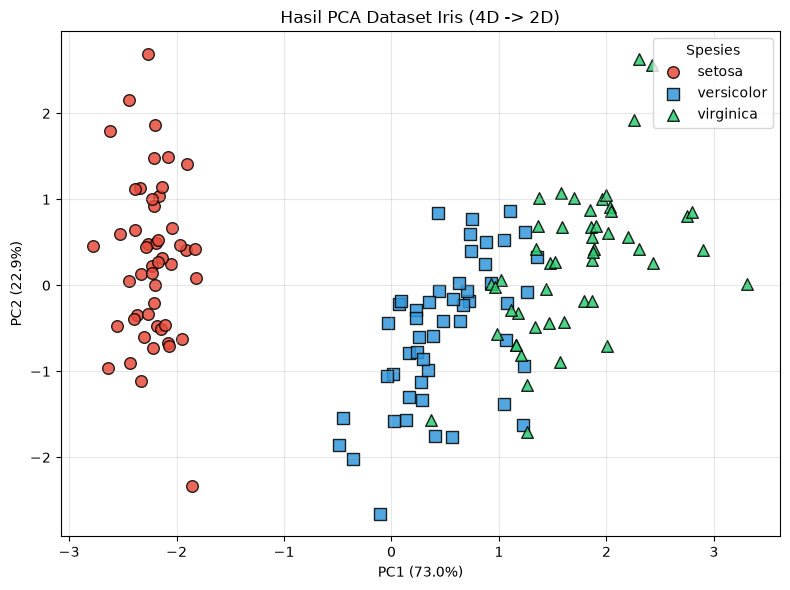

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variansi terjelaskan:", sum(pca.explained_variance_ratio_))

colors = ['#e74c3c', '#3498db', '#2ecc71']
markers = ['o', 's', '^']

fig, ax = plt.subplots(figsize=(8, 6))
for i, target_name in enumerate(target_names):
    idx = y == i
    ax.scatter(X_pca[idx, 0], X_pca[idx, 1], c=colors[i], marker=markers[i],
               label=target_name, edgecolor='k', s=70, alpha=0.85)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Hasil PCA Dataset Iris (4D -> 2D)')
ax.legend(title='Spesies')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pca_scatter.png', dpi=150)
plt.show()